## State-based optimisation for SQEs

In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_state import sqe_optimisation
from pulse_vqe_entanglement.plotting_state import plot_sqe_optimisation

### Strong initiallisation

Tracing control amplitude graph.
Infidelity: I=1.436e-14, nit=5, success=True, grad_norm=1.546e-07, S=5.369e-01
[outer 00] I=2.233e-03, lam=2.233162e+07, inner_nit=105, inner_success=True, constraint_residual=2.233e-03, S=1.029e-01
[outer 01] I=2.354e-16, lam=2.233162e+07, inner_nit=5, inner_success=True, constraint_residual=-9.998e-13, S=1.076e-01
[outer 02] I=2.236e-16, lam=2.233162e+07, inner_nit=1, inner_success=True, constraint_residual=-9.998e-13, S=1.076e-01
[outer 03] I=2.104e-16, lam=2.233162e+07, inner_nit=1, inner_success=True, constraint_residual=-9.998e-13, S=1.076e-01
[outer 04] I=2.104e-16, lam=2.233162e+07, inner_nit=0, inner_success=False, constraint_residual=-9.998e-13, S=1.076e-01


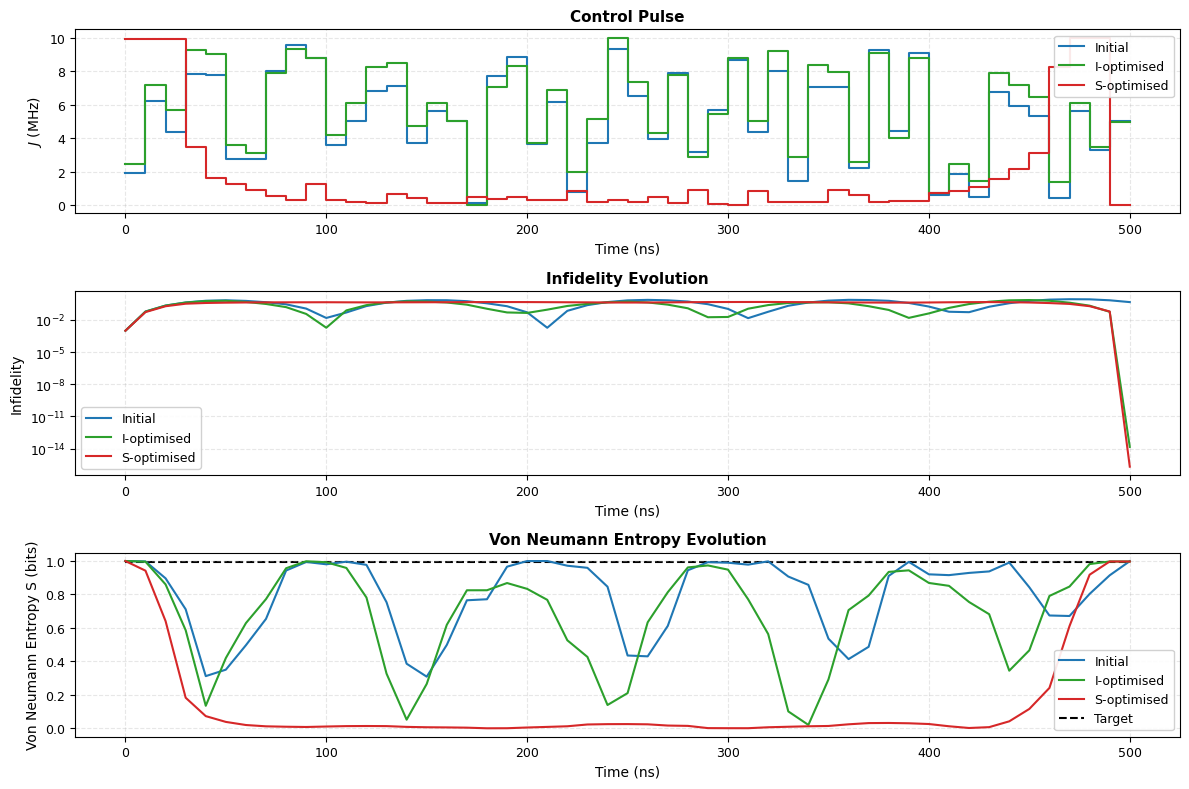

In [2]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 1.0, 0.0]/np.sqrt(2), dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=500.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e0,
    J_init_mean=-0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=1234,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=200,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)

### Weak initialisation

Tracing control amplitude graph.
Infidelity: I=6.515e-13, nit=4, success=True, grad_norm=9.748e-07, S=9.753e-08
[outer 00] I=2.249e-09, lam=2.348283e+01, inner_nit=5, inner_success=True, constraint_residual=2.248e-09, S=9.106e-08
[outer 01] I=4.261e-12, lam=2.351544e+01, inner_nit=2, inner_success=True, constraint_residual=3.261e-12, S=9.539e-08
[outer 02] I=4.346e-12, lam=2.354891e+01, inner_nit=1, inner_success=True, constraint_residual=3.346e-12, S=9.539e-08
[outer 03] I=4.295e-12, lam=2.358185e+01, inner_nit=1, inner_success=True, constraint_residual=3.295e-12, S=9.539e-08
[outer 04] I=4.104e-12, lam=2.361290e+01, inner_nit=1, inner_success=True, constraint_residual=3.104e-12, S=9.539e-08


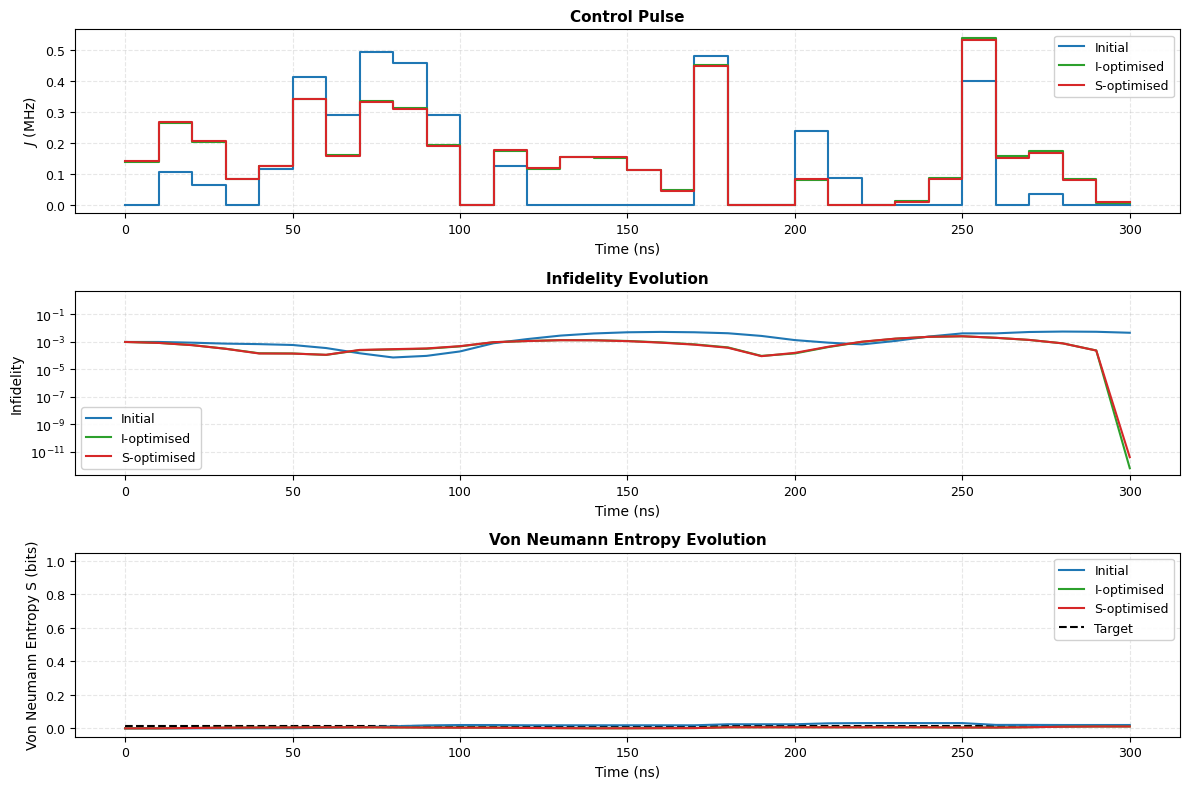

In [3]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0]),
    initial_state=np.array([0.0, 1.0, 0.0, 0.0], dtype=np.complex128),
    theta_target=0.01 * np.pi,
    n_time_steps=30,
    n_discretisation=1,
    T=300.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=-1.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=5,
    inner_maxiter=500,
    fd_eps=1e-6,
)

results = sqe_optimisation(config)
plot_sqe_optimisation(results)